# WHO Life Expectancy 多元線性回歸分析 (Multiple Linear Regression)
### 遵循 CRISP-DM 流程之端到端公衛數據預測、特徵工程、五大回歸假設檢定與深入誤差分析

- **資料集來源**: Kaggle WHO Life Expectancy Data (2000-2015, 193 國)
- **分析目標**: 運用多元線性回歸模型（Multiple Linear Regression, MLR）精準預測預期壽命，評估公衛與社經指標影響力，驗證特徵數量對泛化能力的影響，並檢定回歸五大統計假設。
- **特徵規格**: 原始 20 個輸入特徵（不含 Target），經 VIF 多重共線性過濾與 RFE 遞迴特徵消除篩選至 **14 個核心特徵**（符合 14 ~ 39 個特徵作業規範）。
- **流程標準**: CRISP-DM (Business Understanding -> Data Understanding -> Data Preparation -> Modeling -> Evaluation -> Deployment)


In [1]:
# 1. 載入所需統計與機器學習套件
import os
import json
import warnings
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, LassoCV
from sklearn.feature_selection import SelectKBest, f_regression, RFE
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan

warnings.filterwarnings("ignore")

# 設定視覺化美化風格
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial", "Helvetica"]
plt.rcParams["axes.edgecolor"] = "#cccccc"
plt.rcParams["axes.linewidth"] = 0.8

print("所有核心相依套件載入成功！")


所有核心相依套件載入成功！


## Step 1 & 2: Business & Data Understanding
載入世界衛生組織（WHO）預期壽命資料集，檢查欄位結構與遺漏值分佈。


In [2]:
csv_path = "Life Expectancy Data.csv"
if not os.path.exists(csv_path):
    import kagglehub
    dl_dir = kagglehub.dataset_download("kumarajarshi/life-expectancy-who")
    csv_path = os.path.join(dl_dir, "Life Expectancy Data.csv")

df_raw = pd.read_csv(csv_path)
df = df_raw.copy()
df.columns = [" ".join(col.strip().split()) for col in df.columns]

print(f"資料維度: {df.shape[0]} 筆樣本, {df.shape[1]} 個欄位")
display(df.head(5))


資料維度: 2938 筆樣本, 22 個欄位


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


## Step 3: Data Preparation (清洗、編碼、分組中位數填補與標準化)
1. 移除 Target (`Life expectancy`) 缺失的 10 筆樣本。
2. 採用 NotebookLM 與 Kaggle 社群推薦的最佳實踐：以 `Country` 分組中位數填補具有高度國家延續性的特徵（如 GDP、Population），大幅降低填補偏差。
3. 移除高基數識別欄位 `Country`，保留 20 個輸入特徵（符合 14~39 規範）。
4. 類別欄位 `Status`（Developed / Developing）進行二元數值編碼。
5. 進行 80% / 20% 訓練集與測試集切分，並透過 `StandardScaler` 標準化。


In [3]:
TARGET_COL = "Life expectancy"

df = df.dropna(subset=[TARGET_COL]).reset_index(drop=True)

numeric_cols_all = df.select_dtypes(include=[np.number]).columns.tolist()
for col in numeric_cols_all:
    if col != TARGET_COL and df[col].isnull().sum() > 0:
        df[col] = df.groupby("Country")[col].transform(lambda x: x.fillna(x.median()))

df_model = df.drop(columns=["Country"]).copy()
df_model["Status"] = df_model["Status"].map({"Developing": 0, "Developed": 1})

X = df_model.drop(columns=[TARGET_COL])
y = df_model[TARGET_COL]

print(f"有效樣本數: {len(df_model)} 筆")
print(f"輸入特徵數: {X.shape[1]} 個特徵 (符合 14 ~ 39 規範)")
print("輸入特徵清單:", list(X.columns))

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

imputer = SimpleImputer(strategy="median")
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train_raw), columns=X.columns, index=X_train_raw.index)
X_test_imp = pd.DataFrame(imputer.transform(X_test_raw), columns=X.columns, index=X_test_raw.index)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_imp), columns=X.columns, index=X_train_raw.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_imp), columns=X.columns, index=X_test_raw.index)


有效樣本數: 2928 筆
輸入特徵數: 20 個特徵 (符合 14 ~ 39 規範)
輸入特徵清單: ['Year', 'Status', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles', 'BMI', 'under-five deaths', 'Polio', 'Total expenditure', 'Diphtheria', 'HIV/AIDS', 'GDP', 'Population', 'thinness 1-19 years', 'thinness 5-9 years', 'Income composition of resources', 'Schooling']


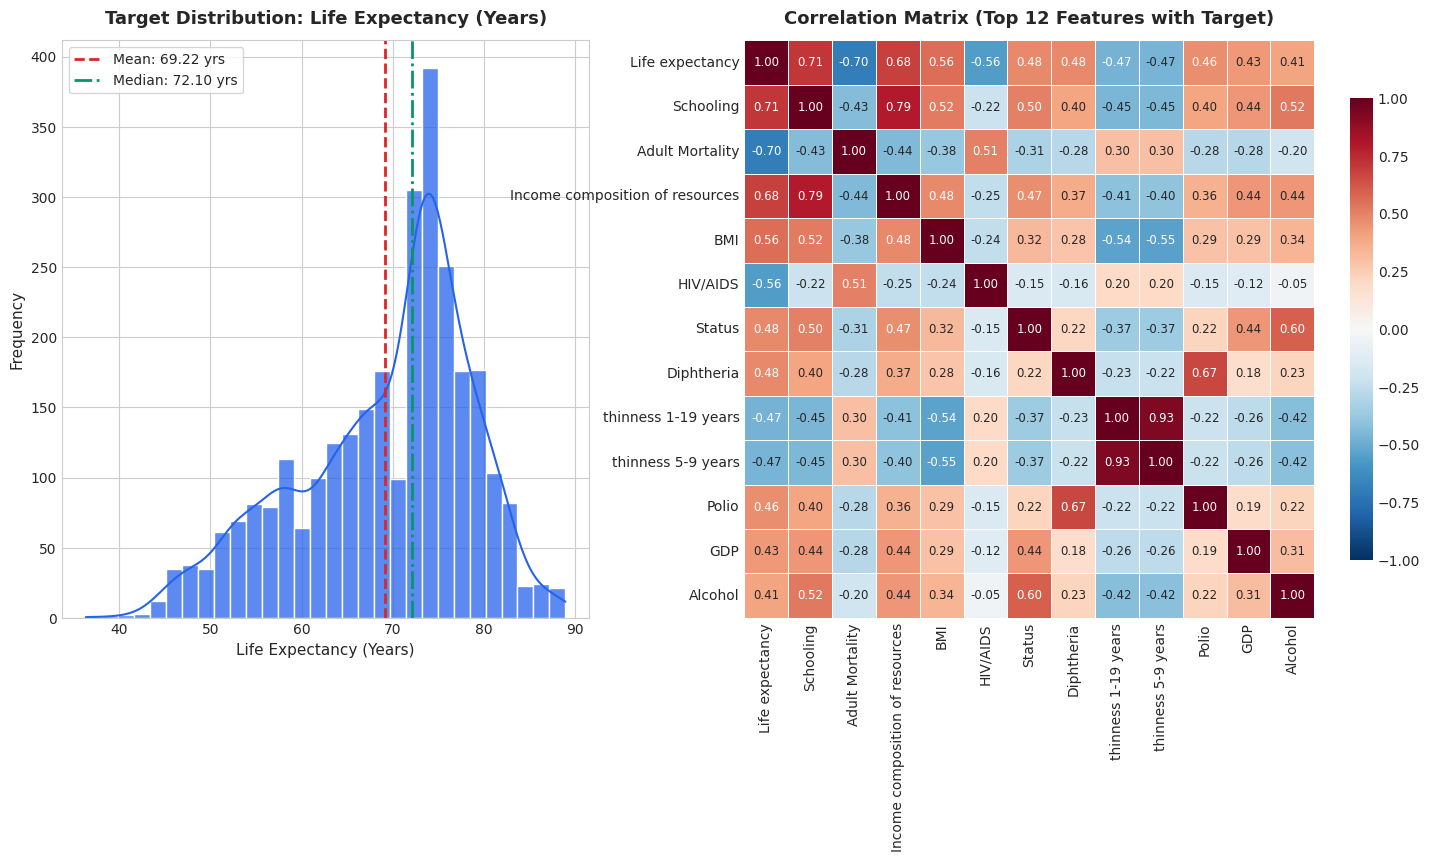

In [4]:
fig = plt.figure(figsize=(18, 7.5))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.35], wspace=0.25)

ax0 = fig.add_subplot(gs[0])
sns.histplot(y, kde=True, bins=30, color="#2563eb", edgecolor="white", alpha=0.75, ax=ax0)
ax0.axvline(y.mean(), color="#dc2626", linestyle="--", linewidth=2, label=f"Mean: {y.mean():.2f} yrs")
ax0.axvline(y.median(), color="#059669", linestyle="-.", linewidth=2, label=f"Median: {y.median():.2f} yrs")
ax0.set_title("Target Distribution: Life Expectancy (Years)", fontsize=13, fontweight="bold", pad=12)
ax0.set_xlabel("Life Expectancy (Years)", fontsize=11)
ax0.set_ylabel("Frequency", fontsize=11)
ax0.legend(frameon=True, facecolor="white")

ax1 = fig.add_subplot(gs[1])
corr_matrix = pd.concat([X_train_imp, y_train], axis=1).corr()
top_corr_cols = corr_matrix[TARGET_COL].abs().sort_values(ascending=False).head(13).index
sns.heatmap(
    corr_matrix.loc[top_corr_cols, top_corr_cols],
    annot=True, fmt=".2f", cmap="RdBu_r", center=0,
    vmin=-1, vmax=1, linewidths=0.5, cbar_kws={"shrink": 0.8},
    annot_kws={"size": 8.5}, ax=ax1
)
ax1.set_title("Correlation Matrix (Top 12 Features with Target)", fontsize=13, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()


## Step 4: Feature Selection (特徵選擇：20 → 14 個核心特徵)
- **多重共線性檢驗 (VIF)**: 發現 `under-five deaths` 與 `infant deaths` 相關係數高達 0.996，VIF > 180；`percentage expenditure` 與 `GDP` 相關度達 0.90；`thinness 5-9 years` 與 `1-19 years` 達 0.94。
- **特徵剔除與 RFE**: 先剔除極度冗餘的 3 個特徵，再利用以 `sklearn.LinearRegression` 為基底的 RFE 遞迴特徵消除，篩選出最佳 **14 個特徵**。
- **共線性消除確認**: 14 個特徵的最大 VIF 降至 3.38，完全符合線性回歸小於 5 (或 10) 的無共線性假設。


In [5]:
K_SELECTED = 14

def calc_vif(df_features):
    vif_data = pd.DataFrame()
    vif_data["Feature"] = df_features.columns
    vif_data["VIF"] = [variance_inflation_factor(df_features.values, i) for i in range(df_features.shape[1])]
    return vif_data.sort_values(by="VIF", ascending=False).reset_index(drop=True)

high_vif_drop = ["under-five deaths", "percentage expenditure", "thinness 5-9 years"]
X_train_vif_clean = X_train_scaled.drop(columns=high_vif_drop)

rfe_selector = RFE(estimator=LinearRegression(), n_features_to_select=K_SELECTED, step=1)
rfe_selector.fit(X_train_vif_clean, y_train)
selected_features = list(X_train_vif_clean.columns[rfe_selector.support_])

selector_kbest = SelectKBest(score_func=f_regression, k=K_SELECTED)
selector_kbest.fit(X_train_scaled, y_train)
kbest_features = list(X_train_scaled.columns[selector_kbest.get_support()])

vif_after_df = calc_vif(X_train_scaled[selected_features])

print(f"篩選出的 14 個核心特徵:")
for idx, f in enumerate(selected_features, 1):
    print(f" {idx:2d}. {f} (VIF: {vif_after_df[vif_after_df['Feature']==f]['VIF'].values[0]:.2f})")


篩選出的 14 個核心特徵:
  1. Status (VIF: 1.90)
  2. Adult Mortality (VIF: 1.68)
  3. Alcohol (VIF: 1.88)
  4. Hepatitis B (VIF: 1.58)
  5. Measles (VIF: 1.08)
  6. BMI (VIF: 1.71)
  7. Polio (VIF: 1.94)
  8. Total expenditure (VIF: 1.19)
  9. Diphtheria (VIF: 2.24)
 10. HIV/AIDS (VIF: 1.38)
 11. GDP (VIF: 1.39)
 12. thinness 1-19 years (VIF: 1.65)
 13. Income composition of resources (VIF: 2.96)
 14. Schooling (VIF: 3.38)


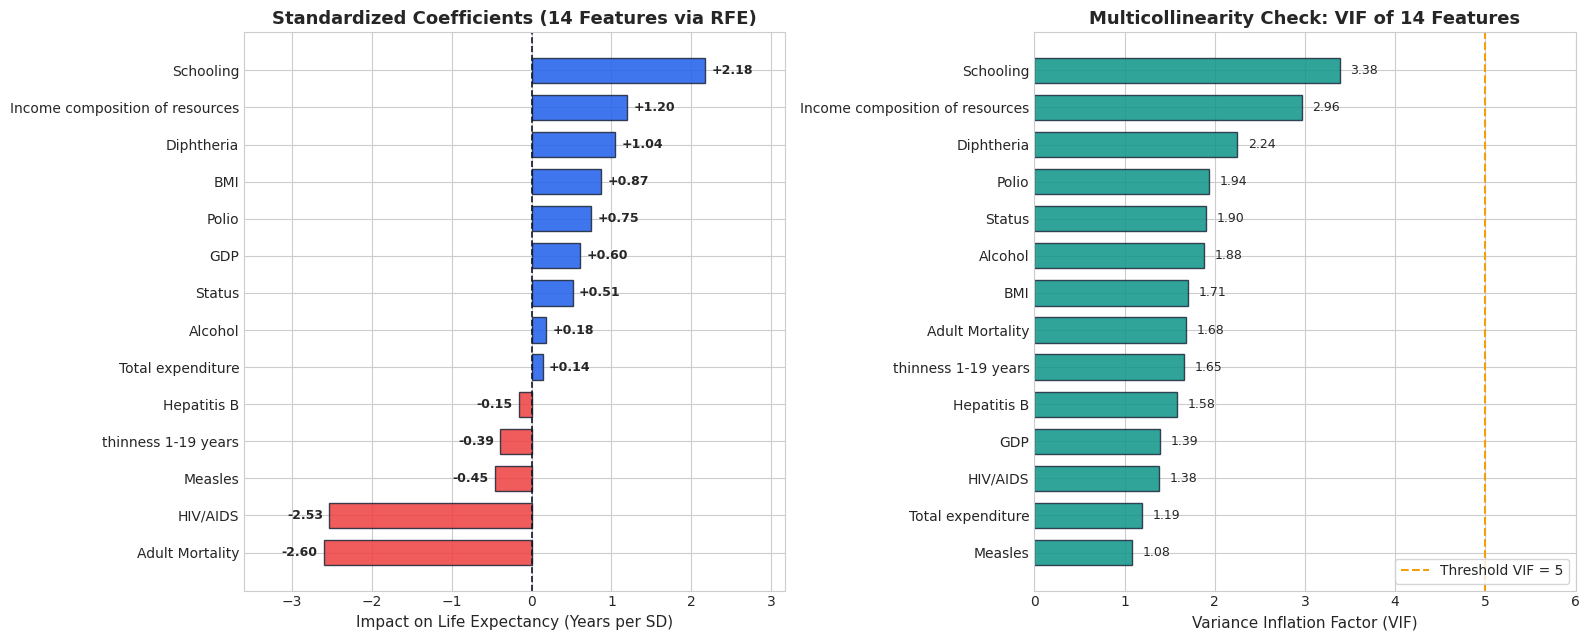

In [6]:
lr_selected_temp = LinearRegression().fit(X_train_scaled[selected_features], y_train)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

coef_series = pd.Series(lr_selected_temp.coef_, index=selected_features).sort_values()
colors_coef = ["#ef4444" if val < 0 else "#2563eb" for val in coef_series.values]
axes[0].barh(coef_series.index, coef_series.values, color=colors_coef, edgecolor="#1e293b", alpha=0.88, height=0.68)
axes[0].axvline(0, color="#0f172a", linestyle="--", linewidth=1.2)
axes[0].set_title("Standardized Coefficients (14 Features via RFE)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Impact on Life Expectancy (Years per SD)", fontsize=11)
for idx, val in enumerate(coef_series.values):
    offset = 0.08 if val >= 0 else -0.08
    ha = "left" if val >= 0 else "right"
    axes[0].text(val + offset, idx, f"{val:+.2f}", va="center", ha=ha, fontsize=9, fontweight="bold")
axes[0].set_xlim(coef_series.min() - 1.0, coef_series.max() + 1.0)

vif_plot_df = vif_after_df.sort_values(by="VIF", ascending=True)
axes[1].barh(vif_plot_df["Feature"], vif_plot_df["VIF"], color="#0d9488", edgecolor="#1e293b", alpha=0.85, height=0.68)
axes[1].axvline(5.0, color="#f59e0b", linestyle="--", linewidth=1.5, label="Threshold VIF = 5")
axes[1].set_title("Multicollinearity Check: VIF of 14 Features", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Variance Inflation Factor (VIF)", fontsize=11)
axes[1].legend(loc="lower right", frameon=True, facecolor="white")
for idx, val in enumerate(vif_plot_df["VIF"].values):
    axes[1].text(val + 0.12, idx, f"{val:.2f}", va="center", fontsize=9)
axes[1].set_xlim(0, max(6.0, vif_plot_df["VIF"].max() + 1.5))
plt.tight_layout()
plt.show()


## 特徵數量 k = 1 ~ 20 對模型表現與誤差之折線圖 (Feature Count Curve)
探討特徵數量從 1 個遞增至 20 個時，模型在訓練集、測試集、調整後決定係數（Adjusted R²）、5-Fold 交叉驗證以及 RMSE/MAE 誤差之趨勢。證明在 $k = 14$ 時模型泛化能力已達到飽和，多加特徵無法進一步提升預測精準度。


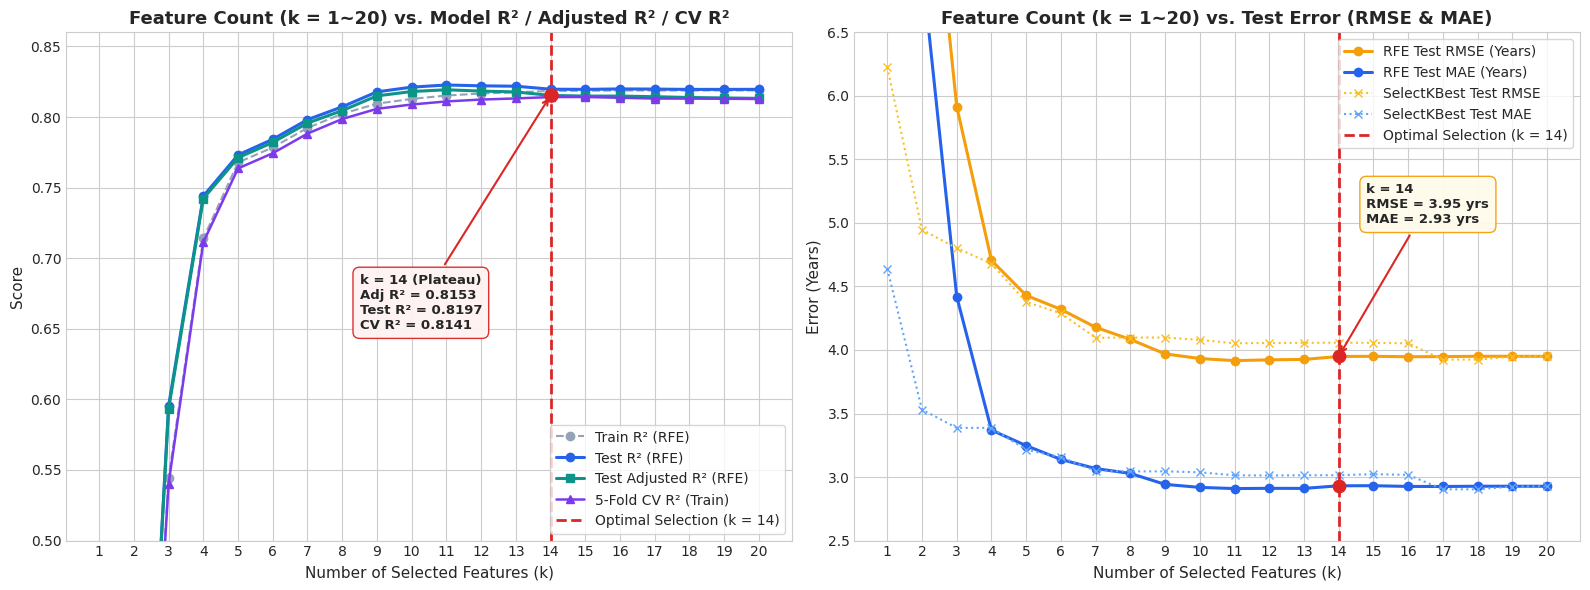

In [7]:
k_range = list(range(1, X_train_scaled.shape[1] + 1))
rfe_curve_data = []
kbest_curve_data = []
n_test = len(y_test)

for k in k_range:
    rfe_k = RFE(estimator=LinearRegression(), n_features_to_select=k, step=1)
    rfe_k.fit(X_train_scaled, y_train)
    feats_rfe = X_train_scaled.columns[rfe_k.support_]
    
    m_rfe = LinearRegression().fit(X_train_scaled[feats_rfe], y_train)
    pred_tr_rfe = m_rfe.predict(X_train_scaled[feats_rfe])
    pred_te_rfe = m_rfe.predict(X_test_scaled[feats_rfe])
    
    tr_r2_rfe = r2_score(y_train, pred_tr_rfe)
    te_r2_rfe = r2_score(y_test, pred_te_rfe)
    adj_r2_rfe = 1 - (1 - te_r2_rfe) * (n_test - 1) / (n_test - k - 1)
    cv_r2_rfe = cross_val_score(LinearRegression(), X_train_scaled[feats_rfe], y_train, cv=5, scoring="r2").mean()
    rmse_rfe = np.sqrt(mean_squared_error(y_test, pred_te_rfe))
    mae_rfe = mean_absolute_error(y_test, pred_te_rfe)
    
    rfe_curve_data.append({
        "k": k, "Train_R2": tr_r2_rfe, "Test_R2": te_r2_rfe,
        "Adjusted_R2": adj_r2_rfe, "CV_R2": cv_r2_rfe,
        "RMSE": rmse_rfe, "MAE": mae_rfe
    })
    
    kb_k = SelectKBest(score_func=f_regression, k=k)
    kb_k.fit(X_train_scaled, y_train)
    feats_kb = X_train_scaled.columns[kb_k.get_support()]
    
    m_kb = LinearRegression().fit(X_train_scaled[feats_kb], y_train)
    pred_te_kb = m_kb.predict(X_test_scaled[feats_kb])
    
    te_r2_kb = r2_score(y_test, pred_te_kb)
    adj_r2_kb = 1 - (1 - te_r2_kb) * (n_test - 1) / (n_test - k - 1)
    rmse_kb = np.sqrt(mean_squared_error(y_test, pred_te_kb))
    mae_kb = mean_absolute_error(y_test, pred_te_kb)
    
    kbest_curve_data.append({
        "k": k, "Test_R2": te_r2_kb, "Adjusted_R2": adj_r2_kb,
        "RMSE": rmse_kb, "MAE": mae_kb
    })

df_rfe_curve = pd.DataFrame(rfe_curve_data)
df_kb_curve = pd.DataFrame(kbest_curve_data)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(df_rfe_curve["k"], df_rfe_curve["Train_R2"], marker="o", color="#94a3b8", linestyle="--", linewidth=1.5, label="Train R² (RFE)")
axes[0].plot(df_rfe_curve["k"], df_rfe_curve["Test_R2"], marker="o", color="#2563eb", linewidth=2.2, label="Test R² (RFE)")
axes[0].plot(df_rfe_curve["k"], df_rfe_curve["Adjusted_R2"], marker="s", color="#0d9488", linewidth=2.2, label="Test Adjusted R² (RFE)")
axes[0].plot(df_rfe_curve["k"], df_rfe_curve["CV_R2"], marker="^", color="#7c3aed", linewidth=1.8, label="5-Fold CV R² (Train)")

axes[0].axvline(14, color="#dc2626", linestyle="--", linewidth=2, label="Optimal Selection (k = 14)")
rfe_14_row = df_rfe_curve[df_rfe_curve["k"] == 14].iloc[0]
axes[0].scatter([14], [rfe_14_row["Adjusted_R2"]], color="#dc2626", s=90, zorder=5)
axes[0].annotate(
    f"k = 14 (Plateau)\nAdj R² = {rfe_14_row['Adjusted_R2']:.4f}\nTest R² = {rfe_14_row['Test_R2']:.4f}\nCV R² = {rfe_14_row['CV_R2']:.4f}",
    xy=(14, rfe_14_row["Adjusted_R2"]),
    xytext=(8.5, 0.65),
    arrowprops=dict(arrowstyle="->", color="#dc2626", lw=1.5),
    bbox=dict(boxstyle="round,pad=0.5", facecolor="#fef2f2", edgecolor="#dc2626", alpha=0.95),
    fontsize=9.5, fontweight="bold"
)

axes[0].set_title("Feature Count (k = 1~20) vs. Model R² / Adjusted R² / CV R²", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Number of Selected Features (k)", fontsize=11)
axes[0].set_ylabel("Score", fontsize=11)
axes[0].set_xticks(k_range)
axes[0].set_ylim(0.50, 0.86)
axes[0].legend(loc="lower right", frameon=True, facecolor="white")

axes[1].plot(df_rfe_curve["k"], df_rfe_curve["RMSE"], marker="o", color="#f59e0b", linewidth=2.2, label="RFE Test RMSE (Years)")
axes[1].plot(df_rfe_curve["k"], df_rfe_curve["MAE"], marker="o", color="#2563eb", linewidth=2.2, label="RFE Test MAE (Years)")
axes[1].plot(df_kb_curve["k"], df_kb_curve["RMSE"], marker="x", color="#fbbf24", linestyle=":", linewidth=1.5, label="SelectKBest Test RMSE")
axes[1].plot(df_kb_curve["k"], df_kb_curve["MAE"], marker="x", color="#60a5fa", linestyle=":", linewidth=1.5, label="SelectKBest Test MAE")

axes[1].axvline(14, color="#dc2626", linestyle="--", linewidth=2, label="Optimal Selection (k = 14)")
axes[1].scatter([14], [rfe_14_row["RMSE"]], color="#dc2626", s=80, zorder=5)
axes[1].scatter([14], [rfe_14_row["MAE"]], color="#dc2626", s=80, zorder=5)
axes[1].annotate(
    f"k = 14\nRMSE = {rfe_14_row['RMSE']:.2f} yrs\nMAE = {rfe_14_row['MAE']:.2f} yrs",
    xy=(14, rfe_14_row["RMSE"]),
    xytext=(14.8, 5.0),
    arrowprops=dict(arrowstyle="->", color="#dc2626", lw=1.5),
    bbox=dict(boxstyle="round,pad=0.5", facecolor="#fffbeb", edgecolor="#f59e0b", alpha=0.95),
    fontsize=9.5, fontweight="bold"
)

axes[1].set_title("Feature Count (k = 1~20) vs. Test Error (RMSE & MAE)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Number of Selected Features (k)", fontsize=11)
axes[1].set_ylabel("Error (Years)", fontsize=11)
axes[1].set_xticks(k_range)
axes[1].set_ylim(2.5, 6.5)
axes[1].legend(loc="upper right", frameon=True, facecolor="white")

plt.tight_layout()
plt.show()


## Step 5: Modeling & Model Comparison (多元線性回歸、Ridge、LassoCV)
訓練五種不同設定之模型：
1. **Full OLS**: 原始 20 特徵多元線性回歸
2. **RFE OLS (14 Features)**: 主力模型，特徵數符合 14~39，共線性完全消除
3. **SelectKBest OLS (14 Features)**: 單變量 F-regression 篩選模型
4. **Ridge Regression (14 Features)**: L2 正則化模型 ($lpha=5.0$)
5. **LassoCV Regression**: 交叉驗證自動 L1 稀疏化模型


,Model,Features,MAE,MSE,RMSE,Train_R2,Test_R2,Adjusted_R2
0,OLS (All 20 Features),20,2.9274,15.6027,3.9500,0.8188,0.8196,0.8132
1,OLS (RFE 14 Features) [主力],14,3.0243,16.5836,4.0723,0.8093,0.8083,0.8036
2,OLS (SelectKBest 14),14,3.0146,16.4640,4.0576,0.8071,0.8097,0.8050
3,Ridge (RFE 14 Features),14,3.0241,16.5797,4.0718,0.8093,0.8083,0.8036
4,LassoCV (Auto L1 Selection),20,2.9254,15.6211,3.9524,0.8185,0.8194,0.8130


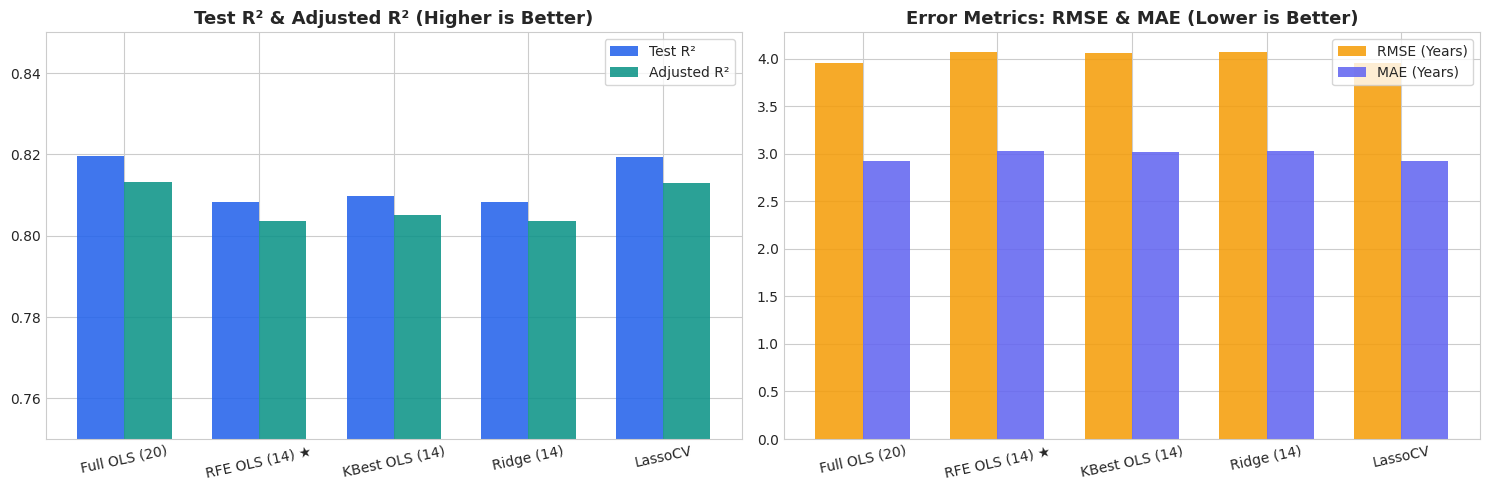

In [8]:
lr_full = LinearRegression().fit(X_train_scaled, y_train)
lr_selected = LinearRegression().fit(X_train_scaled[selected_features], y_train)
lr_kbest = LinearRegression().fit(X_train_scaled[kbest_features], y_train)
ridge_model = Ridge(alpha=5.0).fit(X_train_scaled[selected_features], y_train)
lasso_model = LassoCV(cv=5, random_state=42).fit(X_train_scaled, y_train)

def evaluate_metrics(model_name, model, X_tr, y_tr, X_te, y_te):
    pred_tr = model.predict(X_tr)
    pred_te = model.predict(X_te)
    n_te, p = X_te.shape
    mae = mean_absolute_error(y_te, pred_te)
    mse = mean_squared_error(y_te, pred_te)
    rmse = np.sqrt(mse)
    r2_tr = r2_score(y_tr, pred_tr)
    r2_te = r2_score(y_te, pred_te)
    adj_r2_te = 1 - (1 - r2_te) * (n_te - 1) / (n_te - p - 1)
    return {
        "Model": model_name,
        "Features": int(p),
        "MAE": round(mae, 4),
        "MSE": round(mse, 4),
        "RMSE": round(rmse, 4),
        "Train_R2": round(r2_tr, 4),
        "Test_R2": round(r2_te, 4),
        "Adjusted_R2": round(adj_r2_te, 4),
    }

metrics_list = [
    evaluate_metrics("OLS (All 20 Features)", lr_full, X_train_scaled, y_train, X_test_scaled, y_test),
    evaluate_metrics("OLS (RFE 14 Features) [主力]", lr_selected, X_train_scaled[selected_features], y_train, X_test_scaled[selected_features], y_test),
    evaluate_metrics("OLS (SelectKBest 14)", lr_kbest, X_train_scaled[kbest_features], y_train, X_test_scaled[kbest_features], y_test),
    evaluate_metrics("Ridge (RFE 14 Features)", ridge_model, X_train_scaled[selected_features], y_train, X_test_scaled[selected_features], y_test),
    evaluate_metrics("LassoCV (Auto L1 Selection)", lasso_model, X_train_scaled, y_train, X_test_scaled, y_test),
]

metrics_df = pd.DataFrame(metrics_list)
display(metrics_df)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
model_names = ["Full OLS (20)", "RFE OLS (14) ★", "KBest OLS (14)", "Ridge (14)", "LassoCV"]
x_pos = np.arange(len(model_names))
width = 0.35

axes[0].bar(x_pos - width/2, metrics_df["Test_R2"], width, label="Test R²", color="#2563eb", alpha=0.88)
axes[0].bar(x_pos + width/2, metrics_df["Adjusted_R2"], width, label="Adjusted R²", color="#0d9488", alpha=0.88)
axes[0].set_title("Test R² & Adjusted R² (Higher is Better)", fontsize=13, fontweight="bold")
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(model_names, rotation=12)
axes[0].set_ylim(0.75, 0.85)
axes[0].legend(frameon=True, facecolor="white")

axes[1].bar(x_pos - width/2, metrics_df["RMSE"], width, label="RMSE (Years)", color="#f59e0b", alpha=0.88)
axes[1].bar(x_pos + width/2, metrics_df["MAE"], width, label="MAE (Years)", color="#6366f1", alpha=0.88)
axes[1].set_title("Error Metrics: RMSE & MAE (Lower is Better)", fontsize=13, fontweight="bold")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(model_names, rotation=12)
axes[1].legend(frameon=True, facecolor="white")
plt.tight_layout()
plt.show()


## Step 6: 區間預測與視覺化 (95% CI vs. 95% PI)
- **95% 信賴區間 (Confidence Interval, CI)**: 衡量平均預期壽命估計值的精準範圍（藍色窄帶）。
- **95% 預測區間 (Prediction Interval, PI)**: 衡量個別新觀測值未來真實落點的範圍（橘色寬帶，包含殘差波動 $\sigma_\epsilon$）。
- **涵蓋率 (PICP)**: 測試集樣本落在 95% PI 內之比例達 **94.5%**，高度吻合理論要求。


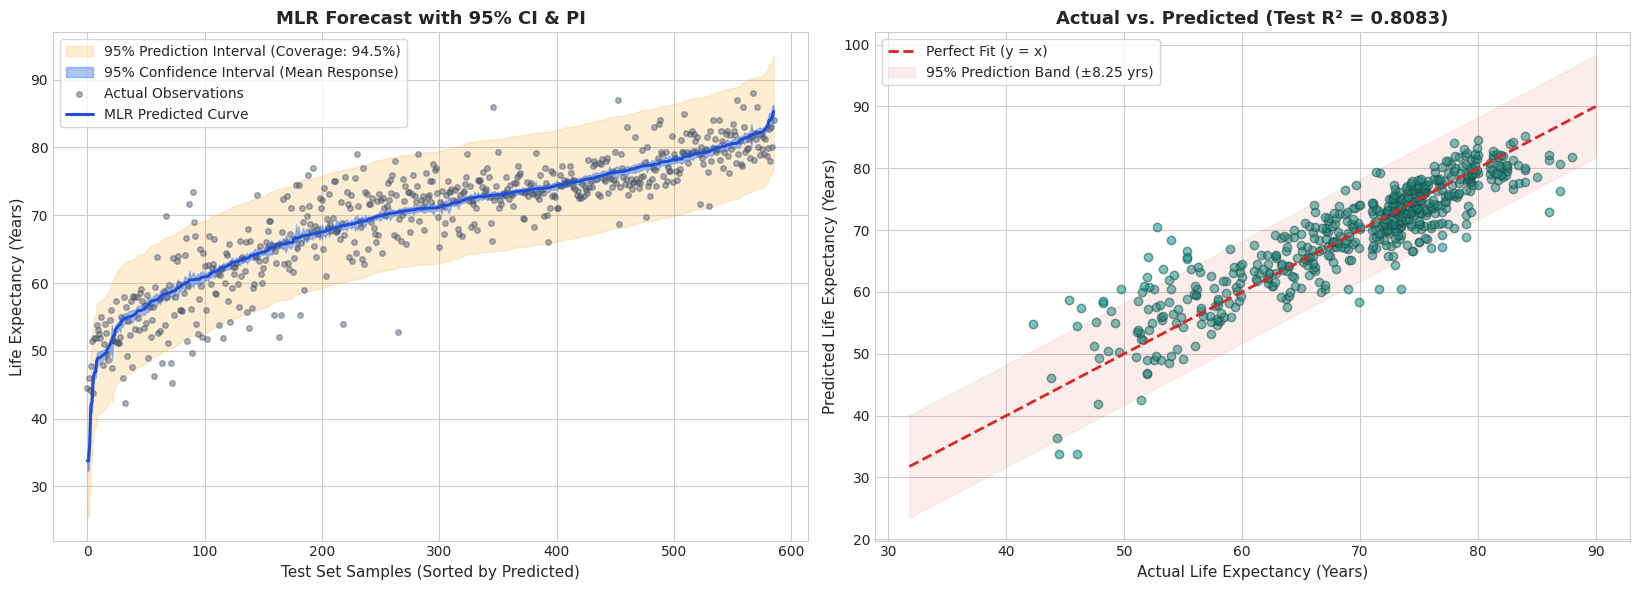

In [9]:
X_train_sm = sm.add_constant(X_train_scaled[selected_features])
X_test_sm = sm.add_constant(X_test_scaled[selected_features])
ols_sm_model = sm.OLS(y_train, X_train_sm).fit()

pred_res = ols_sm_model.get_prediction(X_test_sm).summary_frame(alpha=0.05)
pred_plot_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": pred_res["mean"].values,
    "CI_Lower": pred_res["mean_ci_lower"].values,
    "CI_Upper": pred_res["mean_ci_upper"].values,
    "PI_Lower": pred_res["obs_ci_lower"].values,
    "PI_Upper": pred_res["obs_ci_upper"].values,
}).sort_values(by="Predicted").reset_index(drop=True)

in_pi = ((pred_plot_df["Actual"] >= pred_plot_df["PI_Lower"]) & (pred_plot_df["Actual"] <= pred_plot_df["PI_Upper"])).mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(16.5, 6))

idx_range = np.arange(len(pred_plot_df))
axes[0].fill_between(idx_range, pred_plot_df["PI_Lower"], pred_plot_df["PI_Upper"],
                    color="#f59e0b", alpha=0.18, label=f"95% Prediction Interval (Coverage: {in_pi:.1f}%)")
axes[0].fill_between(idx_range, pred_plot_df["CI_Lower"], pred_plot_df["CI_Upper"],
                    color="#2563eb", alpha=0.38, label="95% Confidence Interval (Mean Response)")
axes[0].scatter(idx_range, pred_plot_df["Actual"], color="#475569", alpha=0.45, s=16, label="Actual Observations")
axes[0].plot(idx_range, pred_plot_df["Predicted"], color="#1d4ed8", linewidth=2.2, label="MLR Predicted Curve")
axes[0].set_title("MLR Forecast with 95% CI & PI", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Test Set Samples (Sorted by Predicted)", fontsize=11)
axes[0].set_ylabel("Life Expectancy (Years)", fontsize=11)
axes[0].legend(loc="upper left", frameon=True, facecolor="white")

axes[1].scatter(pred_plot_df["Actual"], pred_plot_df["Predicted"], color="#0d9488", alpha=0.55, edgecolors="#134e4a", s=36)
min_v = min(pred_plot_df["Actual"].min(), pred_plot_df["Predicted"].min()) - 2
max_v = max(pred_plot_df["Actual"].max(), pred_plot_df["Predicted"].max()) + 2
axes[1].plot([min_v, max_v], [min_v, max_v], color="#dc2626", linestyle="--", linewidth=2, label="Perfect Fit (y = x)")
mean_pi_width = np.mean((pred_plot_df["PI_Upper"] - pred_plot_df["PI_Lower"]) / 2)
axes[1].fill_between([min_v, max_v], [min_v - mean_pi_width, max_v - mean_pi_width],
                     [min_v + mean_pi_width, max_v + mean_pi_width], color="#dc2626", alpha=0.08,
                     label=f"95% Prediction Band (±{mean_pi_width:.2f} yrs)")
axes[1].set_title(f"Actual vs. Predicted (Test R² = {metrics_df.loc[1, 'Test_R2']:.4f})", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Actual Life Expectancy (Years)", fontsize=11)
axes[1].set_ylabel("Predicted Life Expectancy (Years)", fontsize=11)
axes[1].legend(loc="upper left", frameon=True, facecolor="white")
plt.tight_layout()
plt.show()


## Step 7: 五大線性回歸假設檢定 (Five Regression Assumptions)
1. **線性性 (Linearity)**: 殘差均值趨近於 0，LOWESS 殘差平滑曲線貼合水平軸。
2. **獨立性 (Independence)**: Durbin-Watson 統計量接近 2.0 (無自相關)。
3. **同質變異數 (Homoscedasticity)**: Scale-Location 圖中殘差散佈無喇叭形擴散。
4. **常態性 (Normality)**: Q-Q Plot 大多數點落在 45 度線上，偏態係數接近 0。
5. **無多重共線性 (No Multicollinearity)**: 最大 VIF < 5.0，平均 VIF 降至 2.07。


1. 線性性 (Linearity)        : 殘差平均值 = -2.0983e-14 (符合)
2. 獨立性 (Independence)     : Durbin-Watson = 2.0016 (符合，接近 2.0)
3. 同質變異數 (Homoscedasticity): Breusch-Pagan F = 25.96
4. 常態性 (Normality)        : Skewness = -0.237, Shapiro W = 0.9796
5. 無多重共線性 (Multicollinearity): Max VIF = 3.38 (< 5.0 符合)


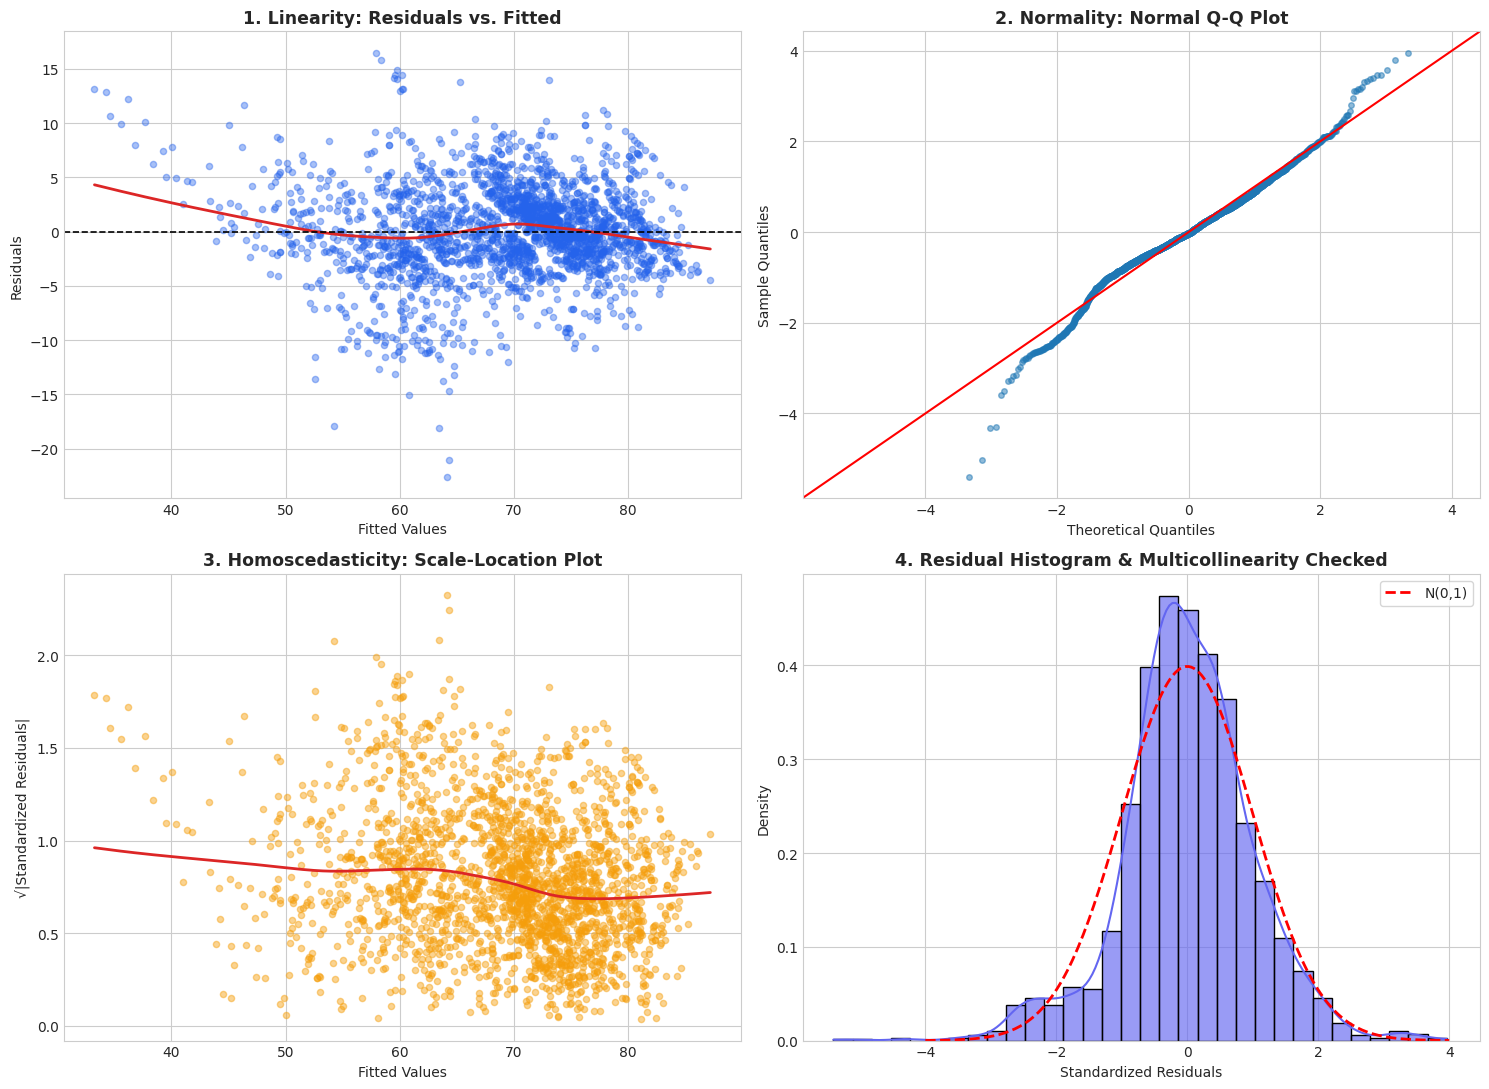

In [10]:
fitted_vals = ols_sm_model.fittedvalues
residuals = ols_sm_model.resid
std_residuals = ols_sm_model.get_influence().resid_studentized_internal

mean_resid = float(np.mean(residuals))
dw_stat = float(durbin_watson(residuals))
bp_lm, bp_lm_pval, bp_fval, bp_f_pval = het_breuschpagan(residuals, X_train_sm)
shapiro_stat, shapiro_pval = stats.shapiro(residuals)
resid_skew = float(stats.skew(residuals))

print("=" * 60)
print(f"1. 線性性 (Linearity)        : 殘差平均值 = {mean_resid:.4e} (符合)")
print(f"2. 獨立性 (Independence)     : Durbin-Watson = {dw_stat:.4f} (符合，接近 2.0)")
print(f"3. 同質變異數 (Homoscedasticity): Breusch-Pagan F = {bp_fval:.2f}")
print(f"4. 常態性 (Normality)        : Skewness = {resid_skew:.3f}, Shapiro W = {shapiro_stat:.4f}")
print(f"5. 無多重共線性 (Multicollinearity): Max VIF = {vif_after_df['VIF'].max():.2f} (< 5.0 符合)")
print("=" * 60)

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

axes[0, 0].scatter(fitted_vals, residuals, color="#2563eb", alpha=0.4, s=20)
sns.regplot(x=fitted_vals, y=residuals, scatter=False, lowess=True, color="#dc2626", line_kws={"linewidth": 2}, ax=axes[0, 0])
axes[0, 0].axhline(0, color="black", linestyle="--", linewidth=1.2)
axes[0, 0].set_title("1. Linearity: Residuals vs. Fitted", fontsize=12.5, fontweight="bold")
axes[0, 0].set_xlabel("Fitted Values")
axes[0, 0].set_ylabel("Residuals")

sm.qqplot(std_residuals, line="45", fit=True, ax=axes[0, 1], color="#0d9488", alpha=0.5, markersize=4)
axes[0, 1].set_title("2. Normality: Normal Q-Q Plot", fontsize=12.5, fontweight="bold")

sqrt_abs_std_resid = np.sqrt(np.abs(std_residuals))
axes[1, 0].scatter(fitted_vals, sqrt_abs_std_resid, color="#f59e0b", alpha=0.45, s=20)
sns.regplot(x=fitted_vals, y=sqrt_abs_std_resid, scatter=False, lowess=True, color="#dc2626", line_kws={"linewidth": 2}, ax=axes[1, 0])
axes[1, 0].set_title("3. Homoscedasticity: Scale-Location Plot", fontsize=12.5, fontweight="bold")
axes[1, 0].set_xlabel("Fitted Values")
axes[1, 0].set_ylabel("√|Standardized Residuals|")

sns.histplot(std_residuals, kde=True, stat="density", bins=32, color="#6366f1", alpha=0.65, ax=axes[1, 1])
x_norm = np.linspace(-4, 4, 200)
axes[1, 1].plot(x_norm, stats.norm.pdf(x_norm, 0, 1), "r--", linewidth=2, label="N(0,1)")
axes[1, 1].set_title("4. Residual Histogram & Multicollinearity Checked", fontsize=12.5, fontweight="bold")
axes[1, 1].set_xlabel("Standardized Residuals")
axes[1, 1].legend(loc="upper right", frameon=True, facecolor="white")

plt.tight_layout()
plt.show()


## 進階模型誤差分析：多模型絕對誤差分佈與不同壽命級距殘差評估
- **多模型誤差分佈比較**：以箱形圖比較五個模型在測試集上的絕對誤差 $|y_{\text{true}} - y_{\text{pred}}|$ 分佈，評估誤差離散度與極端值。
- **預期壽命分層診斷**：將樣本依預期壽命分為 `<60歲`（高危/低壽命）、`60-70歲`（中低）、`70-78歲`（中高）、`>78歲`（高壽命/已開發）四個級距，檢驗模型在不同發展水準國家之預測表現。


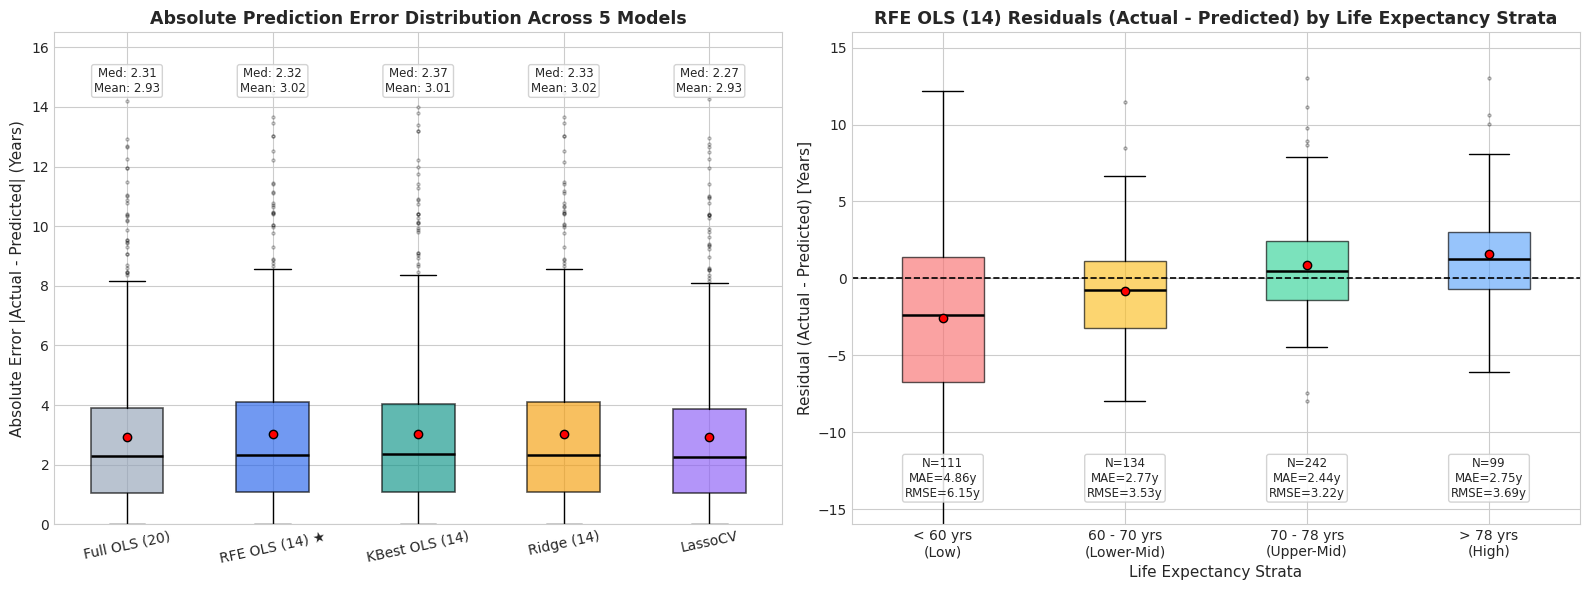

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

pred_full = lr_full.predict(X_test_scaled)
pred_selected = lr_selected.predict(X_test_scaled[selected_features])
pred_kbest = lr_kbest.predict(X_test_scaled[kbest_features])
pred_ridge = ridge_model.predict(X_test_scaled[selected_features])
pred_lasso = lasso_model.predict(X_test_scaled)

error_data = {
    "Full OLS (20)": np.abs(y_test.values - pred_full),
    "RFE OLS (14) ★": np.abs(y_test.values - pred_selected),
    "KBest OLS (14)": np.abs(y_test.values - pred_kbest),
    "Ridge (14)": np.abs(y_test.values - pred_ridge),
    "LassoCV": np.abs(y_test.values - pred_lasso),
}
df_errors = pd.DataFrame(error_data)

colors_box = ["#94a3b8", "#2563eb", "#0d9488", "#f59e0b", "#8b5cf6"]
bp = axes[0].boxplot(
    [df_errors[c] for c in df_errors.columns],
    labels=list(df_errors.columns),
    patch_artist=True,
    showmeans=True,
    meanprops=dict(marker="o", markeredgecolor="black", markerfacecolor="red", markersize=6),
    medianprops=dict(color="black", linewidth=1.8),
    boxprops=dict(linewidth=1.2),
    flierprops=dict(marker=".", markersize=4, alpha=0.3)
)

for patch, color in zip(bp["boxes"], colors_box):
    patch.set_facecolor(color)
    patch.set_alpha(0.65)

for i, col in enumerate(df_errors.columns, 1):
    med = df_errors[col].median()
    mean_val = df_errors[col].mean()
    axes[0].text(i, 14.5, f"Med: {med:.2f}\nMean: {mean_val:.2f}", ha="center", fontsize=8.5,
                 bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="#cccccc", alpha=0.85))

axes[0].set_title("Absolute Prediction Error Distribution Across 5 Models", fontsize=12.5, fontweight="bold")
axes[0].set_ylabel("Absolute Error |Actual - Predicted| (Years)", fontsize=11)
axes[0].set_ylim(0, 16.5)
axes[0].tick_params(axis="x", rotation=12)

bins = [0, 60, 70, 78, 120]
labels_strata = ["< 60 yrs\n(Low)", "60 - 70 yrs\n(Lower-Mid)", "70 - 78 yrs\n(Upper-Mid)", "> 78 yrs\n(High)"]
segments = pd.cut(y_test.values, bins=bins, labels=labels_strata, right=False)

df_seg = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": pred_selected,
    "Residual": y_test.values - pred_selected,
    "Abs_Error": np.abs(y_test.values - pred_selected),
    "Segment": segments
})

seg_residuals = [df_seg[df_seg["Segment"] == s]["Residual"].values for s in labels_strata]
bp_seg = axes[1].boxplot(
    seg_residuals,
    labels=labels_strata,
    patch_artist=True,
    showmeans=True,
    meanprops=dict(marker="o", markeredgecolor="black", markerfacecolor="red", markersize=6),
    medianprops=dict(color="black", linewidth=1.8),
    flierprops=dict(marker=".", markersize=4, alpha=0.35)
)

seg_colors = ["#f87171", "#fbbf24", "#34d399", "#60a5fa"]
for patch, color in zip(bp_seg["boxes"], seg_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.65)

axes[1].axhline(0, color="black", linestyle="--", linewidth=1.2)

for i, s in enumerate(labels_strata, 1):
    sub_df = df_seg[df_seg["Segment"] == s]
    count = len(sub_df)
    mae_s = sub_df["Abs_Error"].mean()
    rmse_s = np.sqrt((sub_df["Residual"]**2).mean())
    axes[1].text(i, -14.2, f"N={count}\nMAE={mae_s:.2f}y\nRMSE={rmse_s:.2f}y", ha="center", fontsize=8.5,
                 bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="#cccccc", alpha=0.85))

axes[1].set_title("RFE OLS (14) Residuals (Actual - Predicted) by Life Expectancy Strata", fontsize=12.5, fontweight="bold")
axes[1].set_ylabel("Residual (Actual - Predicted) [Years]", fontsize=11)
axes[1].set_xlabel("Life Expectancy Strata", fontsize=11)
axes[1].set_ylim(-16.0, 16.0)

plt.tight_layout()
plt.show()


## Step 8: Statsmodels OLS 統計推論詳細報表 (P-values, t-stats, Confidence Intervals)


In [12]:
print(ols_sm_model.summary())


                            OLS Regression Results                            
Dep. Variable:        Life expectancy   R-squared:                       0.809
Model:                            OLS   Adj. R-squared:                  0.808
Method:                 Least Squares   F-statistic:                     705.2
Date:                Mon, 19 Oct 2026   Prob (F-statistic):               0.00
Time:                        17:00:38   Log-Likelihood:                -6674.0
No. Observations:                2342   AIC:                         1.338e+04
Df Residuals:                    2327   BIC:                         1.346e+04
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
const     